<a href="https://colab.research.google.com/github/emilytiari/Python/blob/main/Eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Análise exploratória de dados (EDA)

Exploratory Data Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [ ]:
df=pd.read_csv("/content/dataset_aula8_eda - dataset_aula8_eda.csv")
df.head()

,id_registro,setor,turno,temperatura_c,tempo_ciclo_s,producao_dia,consumo_kwh,vibracao_mm_s,falha
0,1,Montagem,C,63.75,37.53,102,102.49,2.23,0
1,2,Montagem,C,69.46,39.53,154,144.24,4.93,1
2,3,Usinagem,B,64.72,37.68,89,142.78,1.10,0
3,4,Usinagem,B,72.90,34.84,90,129.69,3.76,0
4,5,Montagem,C,77.50,40.35,134,114.61,2.31,0


In [ ]:
print("Dimensões da base: ", df.shape)
print("\nColunas")
print(df.columns)

Dimensões da base:  (120, 9)

Colunas
Index(['id_registro', 'setor', 'turno', 'temperatura_c', 'tempo_ciclo_s',
       'producao_dia', 'consumo_kwh', 'vibracao_mm_s', 'falha'],
      dtype='object')


In [ ]:
df.dtypes

,0
id_registro,int64
setor,object
turno,object
temperatura_c,float64
tempo_ciclo_s,float64
producao_dia,int64
consumo_kwh,float64
vibracao_mm_s,float64
falha,int64


In [ ]:
df.describe()

,id_registro,temperatura_c,tempo_ciclo_s,producao_dia,consumo_kwh,vibracao_mm_s,falha
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000
mean,60.500000,74.185833,34.356667,124.691667,119.132417,3.018667,0.191667
std,34.785054,6.131015,5.454882,23.975406,22.600777,0.848350,0.395263
min,1.000000,58.650000,20.170000,87.000000,69.070000,1.030000,0.000000
25%,30.750000,70.422500,31.130000,104.000000,102.557500,2.365000,0.000000
50%,60.500000,74.060000,34.505000,126.000000,117.020000,2.935000,0.000000
75%,90.250000,77.690000,37.127500,146.250000,133.660000,3.652500,0.000000
max,120.000000,101.000000,61.000000,164.000000,205.000000,5.220000,1.000000


In [ ]:
df.isnull().sum()

,0
id_registro,0
setor,0
turno,0
temperatura_c,0
tempo_ciclo_s,0
producao_dia,0
consumo_kwh,0
vibracao_mm_s,0
falha,0


In [ ]:
print("Contagem por setor")
print(df["setor"].value_counts())

print("Contagem por turno")
print(df["turno"].value_counts())

print("Contagem de falha")
print(df["falha"].value_counts())

Contagem por setor
setor
Montagem    48
Usinagem    47
Inspeção    25
Name: count, dtype: int64
Contagem por turno
turno
B    45
C    44
A    31
Name: count, dtype: int64
Contagem de falha
falha
0    97
1    23
Name: count, dtype: int64


#Visualização inicial- histograma

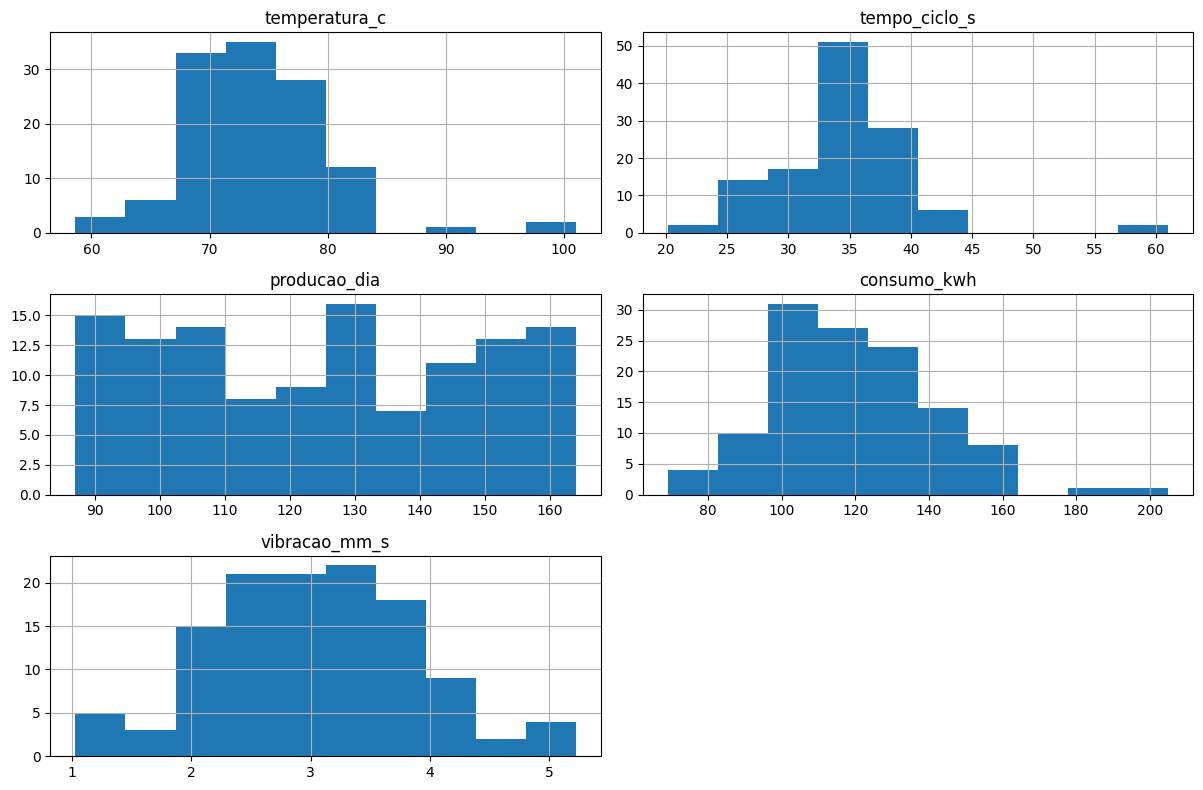

In [ ]:
df[[
    "temperatura_c",
    "tempo_ciclo_s",
    "producao_dia",
    "consumo_kwh",
    "vibracao_mm_s"
]].hist(figsize=(12,8))
plt.tight_layout()
plt.show()

Correlação

In [ ]:
correlacao=df[[
    "temperatura_c",
    "tempo_ciclo_s",
    "producao_dia",
    "consumo_kwh",
    "vibracao_mm_s",
    "falha"
]].corr()
correlacao

,temperatura_c,tempo_ciclo_s,producao_dia,consumo_kwh,vibracao_mm_s,falha
temperatura_c,1.000000,0.039718,0.093406,-0.146495,0.099302,0.030882
tempo_ciclo_s,0.039718,1.000000,0.080320,-0.020028,0.105455,0.173190
producao_dia,0.093406,0.080320,1.000000,0.012397,0.037068,0.050626
consumo_kwh,-0.146495,-0.020028,0.012397,1.000000,-0.066480,0.342056
vibracao_mm_s,0.099302,0.105455,0.037068,-0.066480,1.000000,0.314779
falha,0.030882,0.173190,0.050626,0.342056,0.314779,1.000000


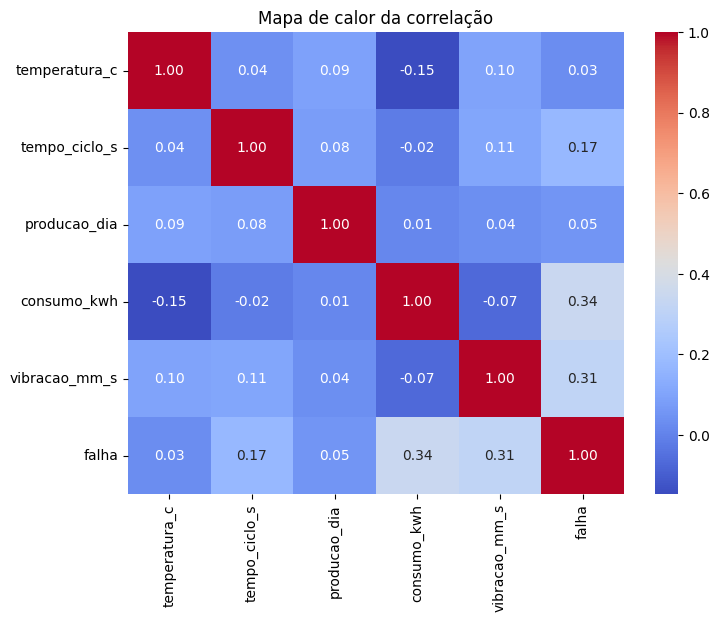

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Mapa de calor da correlação")
plt.show()

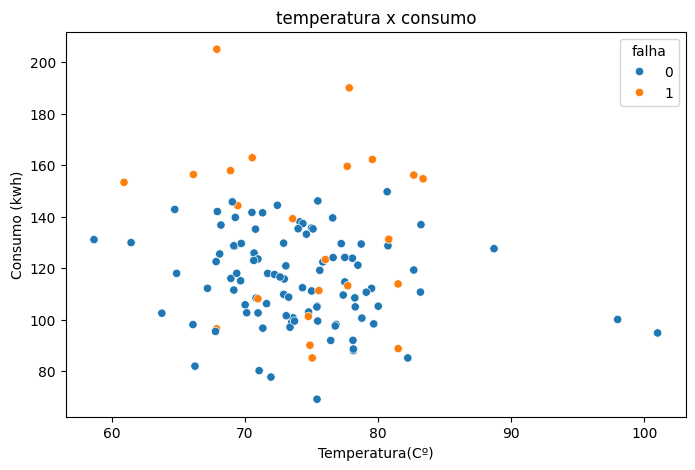

In [ ]:
# Grafico de dispersão
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="temperatura_c",
    y="consumo_kwh",
    hue="falha"
)
plt.title("temperatura x consumo")
plt.xlabel("Temperatura(Cº)")
plt.ylabel("Consumo (kwh)")
plt.show()

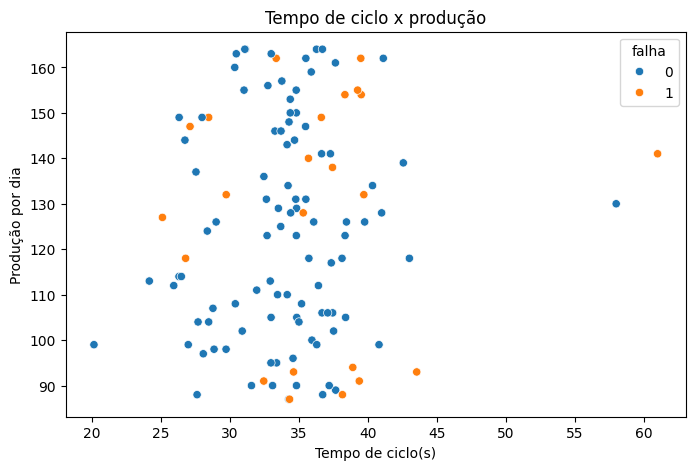

In [ ]:
#Grafico de dispersão de tempo ciclo
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="tempo_ciclo_s",
    y="producao_dia",
    hue="falha"
)
plt.title("Tempo de ciclo x produção")
plt.xlabel("Tempo de ciclo(s)")
plt.ylabel("Produção por dia")
plt.show()

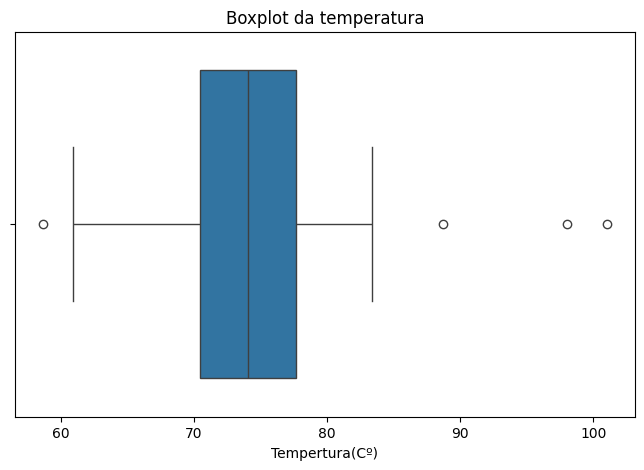

In [ ]:
#Encontrando outliers com boxplot
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="temperatura_c"
)
plt.title("Boxplot da temperatura")
plt.xlabel("Tempertura(Cº)")
plt.show()

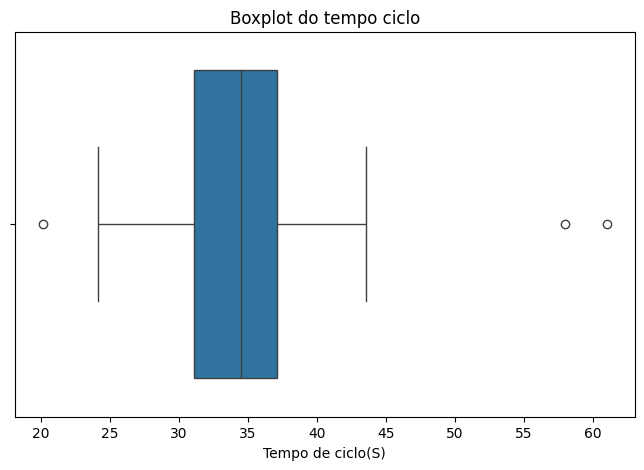

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="tempo_ciclo_s"
)
plt.title("Boxplot do tempo ciclo")
plt.xlabel("Tempo de ciclo(S)")
plt.show()

In [ ]:
#identificando outliers
Q1=df["temperatura_c"].quantile(0.25)
Q3=df["temperatura_c"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 -1.5 * IQR
limite_superior = Q3 +1.5 * IQR

outliers_temp = df[(
    df["temperatura_c"]<limite_inferior
)|(df["temperatura_c"]> limite_superior)]

print("Q1:",Q1)
print("Q2:",Q3)
print("IQR",IQR)
print("Limite inferior:", limite_inferior)
print("Limite Superior:", limite_superior)

print("\nOutliers de temperatura:")
print(outliers_temp[[
          "id_registro",
          "temperatura_c",
          "setor",
          "falha"
      ]])

Q1: 70.4225
Q2: 77.69
IQR 7.267499999999998
Limite inferior: 59.52125
Limite Superior: 88.59125

Outliers de temperatura:
     id_registro  temperatura_c     setor  falha
70            71         101.00  Inspeção      0
81            82          88.71  Montagem      0
102          103          98.00  Montagem      0
104          105          58.65  Inspeção      0


#Identificar padrões por grupo

In [ ]:
print("Média da temperatura por setor: ")
print(df.groupby("setor")["temperatura_c"].mean())

print("Média da consumo por turno: ")
print(df.groupby("turno")["consumo_kwh"].mean())

print("\nTaxa de falha por setor: ")
print(df.groupby("setor")["falha"].mean())


Média da temperatura por setor: 
setor
Inspeção    73.944400
Montagem    74.818958
Usinagem    73.667660
Name: temperatura_c, dtype: float64
Média da consumo por turno: 
turno
A    119.971613
B    119.138889
C    118.534545
Name: consumo_kwh, dtype: float64

Taxa de falha por setor: 
setor
Inspeção    0.240000
Montagem    0.187500
Usinagem    0.170213
Name: falha, dtype: float64


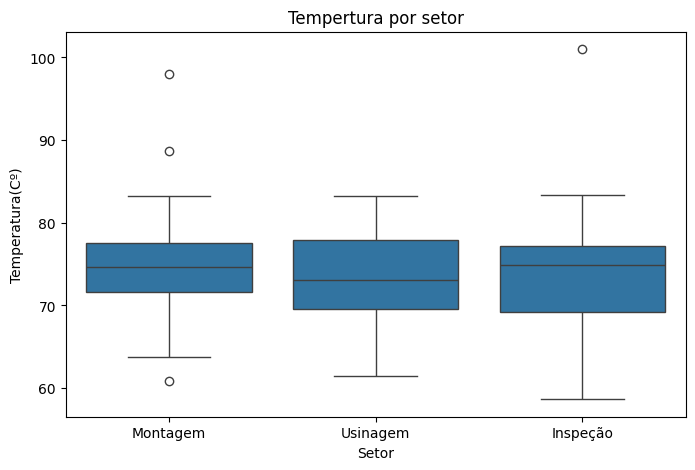

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="setor",
    y="temperatura_c"
)
plt.title("Tempertura por setor")
plt.xlabel("Setor")
plt.ylabel("Temperatura(Cº)")
plt.show()